In [82]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from google.colab import files

In [83]:
uploads = files.upload()

print("Arquivos enviados:")

for nome in uploads:
    print(nome)

Saving Segunda Foto.jpeg to Segunda Foto (6).jpeg
Saving Terceira Foto.jpeg to Terceira Foto (8).jpeg
Saving Primeira foto.jpeg to Primeira foto (8).jpeg
Arquivos enviados:
Segunda Foto (6).jpeg
Terceira Foto (8).jpeg
Primeira foto (8).jpeg


## Operação escolhida e parâmetros

Foi utilizada uma única operação em cada imagem: a correção de gamma. Essa transformação permite ajustar a luminosidade dos tons intermediários de maneira não linear.

Na implementação utilizada, valores de gamma menores que 1 clareiam os tons intermediários, enquanto valores maiores que 1 os escurecem. O valor 1 mantém as intensidades originais.

### Imagem escura — γ = 0,5

A correção foi escolhida para clarear as regiões escuras e facilitar a visualização dos detalhes na área coberta. O parâmetro 0,5 aumentou as intensidades intermediárias, tornando essas regiões mais visíveis.

### Segunda imagem — γ = 1,8

O parâmetro 1,8 foi aplicado com o objetivo inicial de reduzir a luminosidade de uma imagem considerada clara. Entretanto, a análise do histograma mostrou que a fotografia já possuía muitos tons escuros e intermediários, e a transformação escureceu excessivamente algumas regiões. Portanto, esse ajuste não foi adequado para melhorar a exposição desta fotografia.

### Imagem bem exposta — γ = 0,9

Foi escolhido um parâmetro próximo de 1 para realizar um clareamento suave, pois a imagem já apresentava detalhes visíveis e uma exposição considerada adequada. O resultado manteve uma aparência próxima à original.

In [84]:
imgEscura = cv2.imread("Primeira foto.jpeg")
imgClara = cv2.imread("Segunda Foto.jpeg")
imgBoa = cv2.imread("Terceira Foto.jpeg")

if imgEscura is None:
    raise ValueError("A imagem escura não foi carregada. Confira o nome do arquivo.")

if imgClara is None:
    raise ValueError("A imagem clara não foi carregada. Confira o nome do arquivo.")

if imgBoa is None:
    raise ValueError("A imagem bem exposta não foi carregada. Confira o nome do arquivo.")

print("As três imagens foram carregadas corretamente.")

As três imagens foram carregadas corretamente.


In [85]:
imgEscuraGRAY = cv2.cvtColor(imgEscura, cv2.COLOR_BGR2GRAY)
imgClaraGRAY = cv2.cvtColor(imgClara, cv2.COLOR_BGR2GRAY)
imgBoaGRAY = cv2.cvtColor(imgBoa, cv2.COLOR_BGR2GRAY)

In [86]:
def calculo_histograma(img):

    imgVetor = img.ravel()

    histogramaVetor = np.zeros(256)

    for px in imgVetor:
        histogramaVetor[px] += 1

    return histogramaVetor

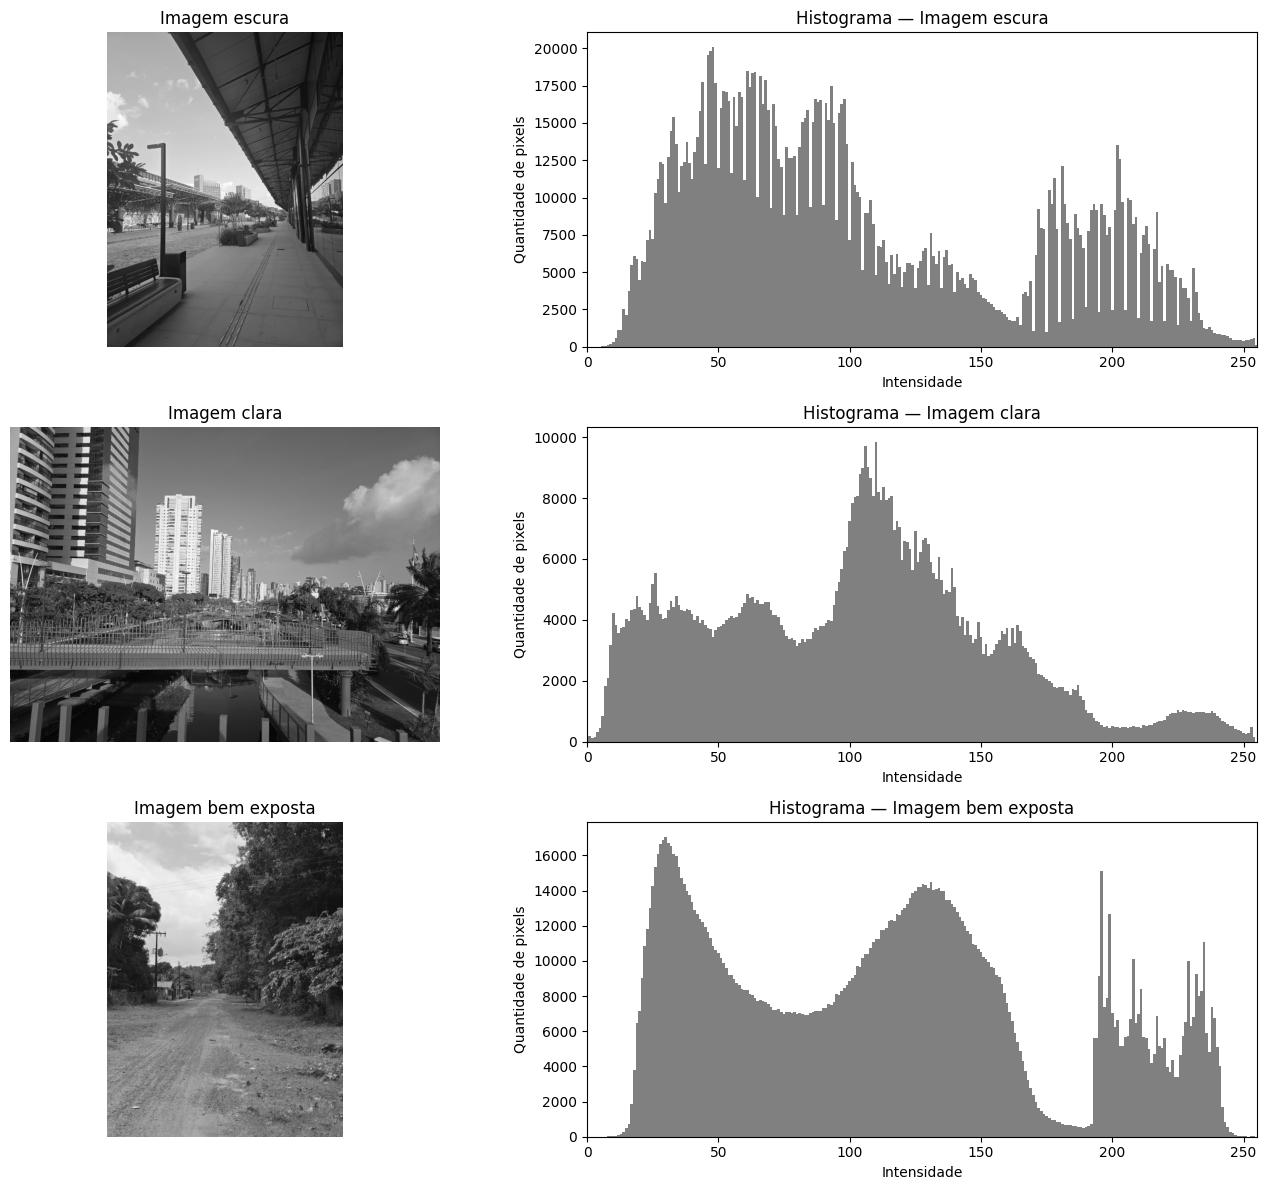

In [87]:
imagens = [imgEscuraGRAY, imgClaraGRAY, imgBoaGRAY]
titulos = ["Imagem escura", "Imagem clara", "Imagem bem exposta"]

fig, ax = plt.subplots(3, 2, figsize=(14, 12))

for i in range(3):

    ax[i, 0].imshow(imagens[i], cmap="gray", vmin=0, vmax=255)
    ax[i, 0].set_title(titulos[i])
    ax[i, 0].axis("off")

    histograma = calculo_histograma(imagens[i])

    ax[i, 1].bar(np.arange(256), histograma, width=1, color="gray")
    ax[i, 1].set_title("Histograma — " + titulos[i])
    ax[i, 1].set_xlabel("Intensidade")
    ax[i, 1].set_ylabel("Quantidade de pixels")
    ax[i, 1].set_xlim(0, 255)

plt.tight_layout()
plt.show()

## Diagnóstico dos histogramas

### Imagem escura

O histograma mostra uma aglomeração significativa de pixels na faixa aproximada entre 25 e 100, o que revela numerosas áreas escuras, sobretudo na região coberta. Há também valores de intensidade elevados, relacionados às partes mais iluminadas da cena.

### Segunda imagem

O histograma apresenta maior densidade nos tons escuros e médios, com um principal pico por volta de 100 a 120. Mesmo com a existência de zonas claras, a configuração da distribuição e a percepção da imagem não sugerem que se trate de uma fotografia excessivamente clara.
### Imagem bem exposta

O histograma exibe intensidades espalhadas ao longo de uma ampla faixa, com concentrações aproximadas entre 25 e 60, entre 90 e 160 e entre 195 e 240. Essa distribuição corresponde à presença de sombras, tons médios e áreas claras, permitindo a visualização de detalhes em distintas partes da cena.

In [88]:
def corrigir_gamma(img, gamma):

    if gamma <= 0:
        raise ValueError("O valor de gamma deve ser maior que zero.")

    imgFloat = img.astype(np.float32)

    imgNormalizada = imgFloat / 255.0

    imgCorrigida = 255.0 * (imgNormalizada ** gamma)

    imgCorrigida = np.clip(np.round(imgCorrigida), 0, 255)

    return imgCorrigida.astype(np.uint8)

In [89]:
gammaEscura = 0.5
gammaClara = 1.8
gammaBoa = 0.9

imgEscuraCorrigida = corrigir_gamma(imgEscuraGRAY, gammaEscura)
imgClaraCorrigida = corrigir_gamma(imgClaraGRAY, gammaClara)
imgBoaCorrigida = corrigir_gamma(imgBoaGRAY, gammaBoa)

In [90]:
def mostrar_comparacao(original, corrigida, titulo, gamma):

    histOriginal = calculo_histograma(original)
    histCorrigido = calculo_histograma(corrigida)

    limiteY = max(histOriginal.max(), histCorrigido.max()) * 1.05

    fig, ax = plt.subplots(2, 2, figsize=(12, 8))

    ax[0, 0].imshow(original, cmap="gray", vmin=0, vmax=255)
    ax[0, 0].set_title("Antes")
    ax[0, 0].axis("off")

    ax[0, 1].imshow(corrigida, cmap="gray", vmin=0, vmax=255)
    ax[0, 1].set_title(f"Depois — gamma = {gamma}")
    ax[0, 1].axis("off")

    ax[1, 0].bar(
        np.arange(256), histOriginal, width=1, color="gray"
    )
    ax[1, 0].set_title("Histograma antes")

    ax[1, 1].bar(
        np.arange(256), histCorrigido, width=1, color="gray"
    )
    ax[1, 1].set_title("Histograma depois")

    for i in range(2):
        ax[1, i].set_xlabel("Intensidade")
        ax[1, i].set_ylabel("Quantidade de pixels")
        ax[1, i].set_xlim(0, 255)
        ax[1, i].set_ylim(0, limiteY)

    fig.suptitle(titulo, fontsize=16)

    plt.tight_layout()
    plt.show()

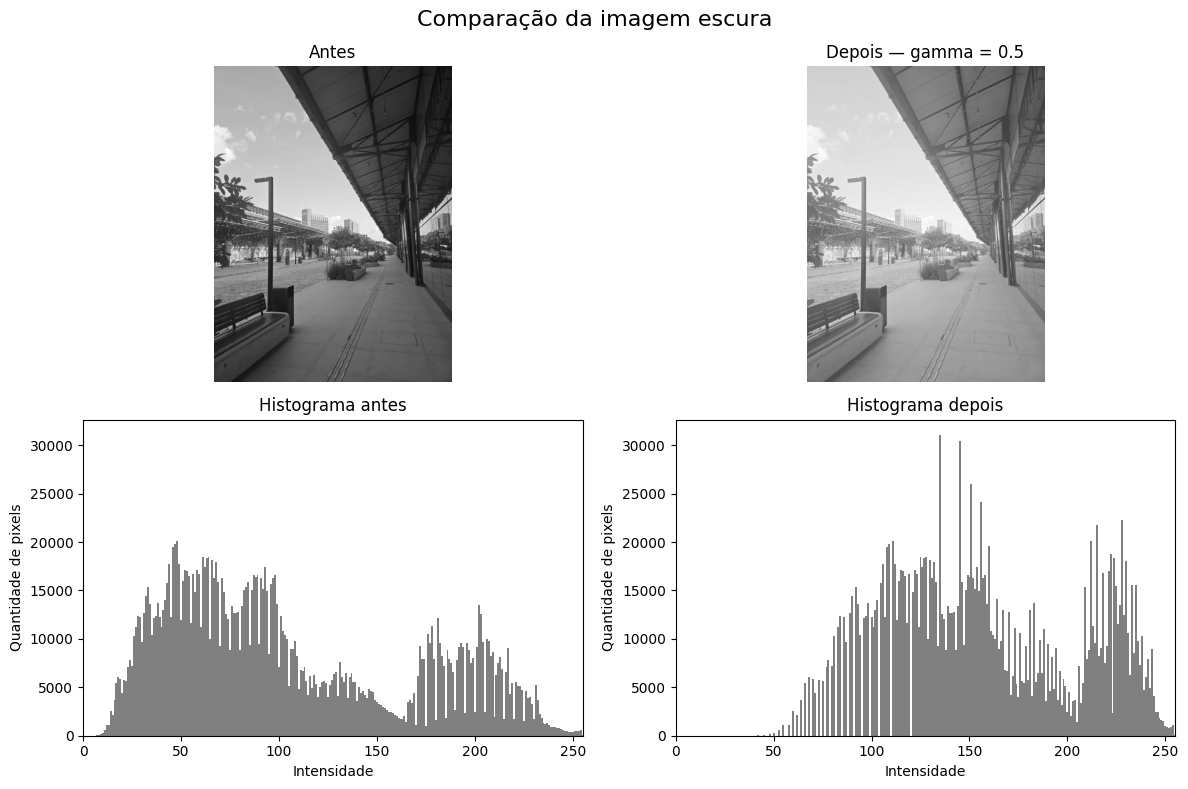

In [91]:
mostrar_comparacao(
    imgEscuraGRAY,
    imgEscuraCorrigida,
    "Comparação da imagem escura",
    gammaEscura
)

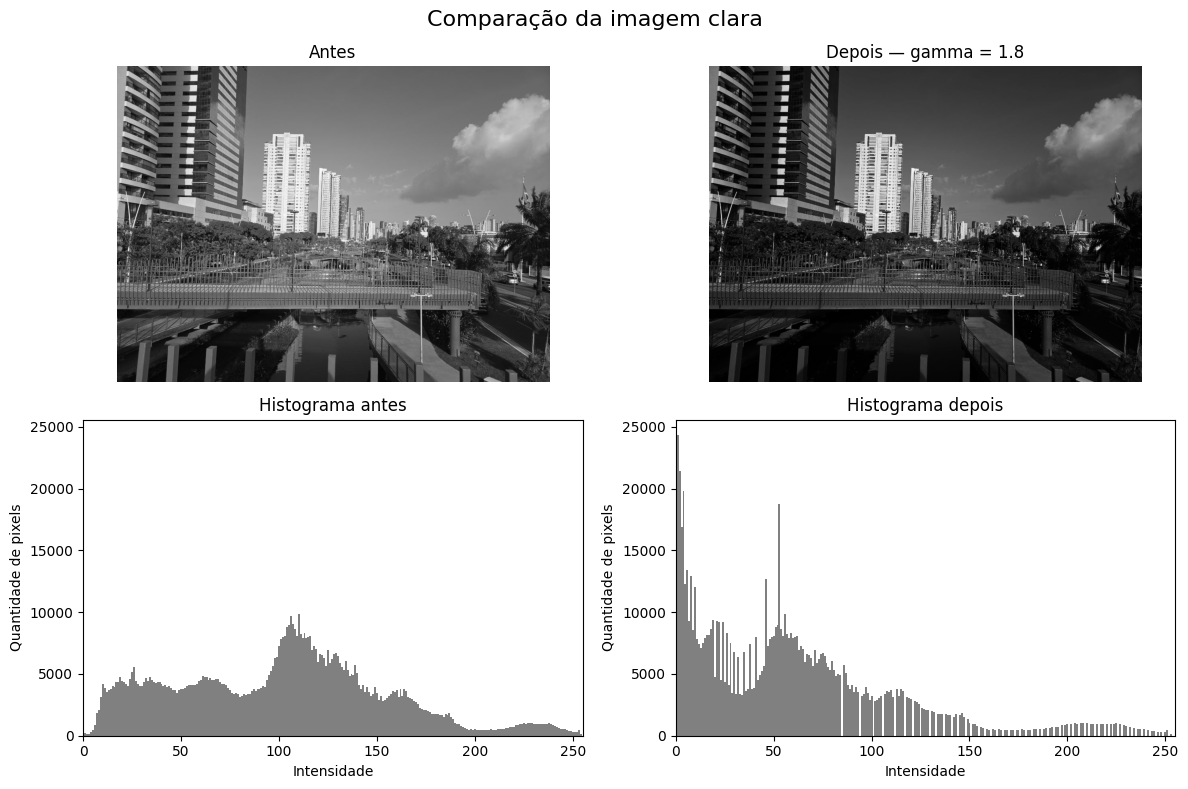

In [92]:
mostrar_comparacao(
    imgClaraGRAY,
    imgClaraCorrigida,
    "Comparação da imagem clara",
    gammaClara
)

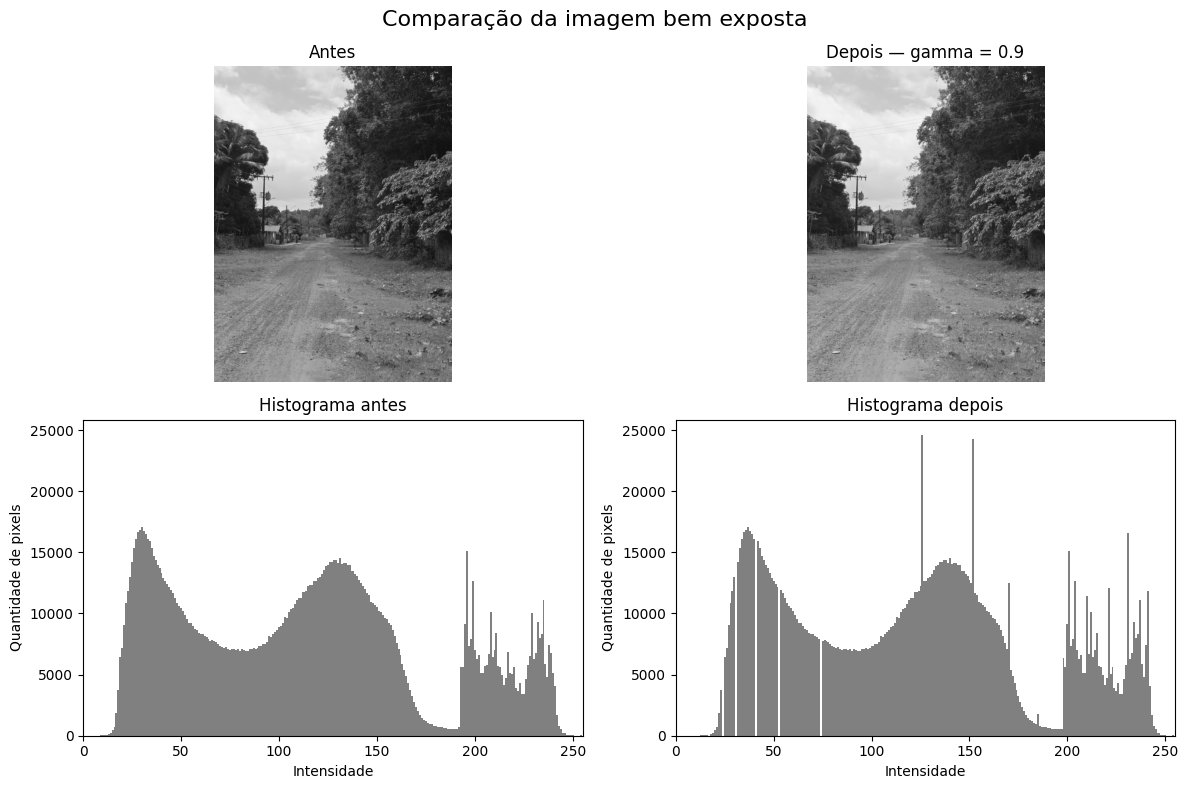

In [93]:
mostrar_comparacao(
    imgBoaGRAY,
    imgBoaCorrigida,
    "Comparação da imagem bem exposta",
    gammaBoa
)

## Em qual imagem a operação fez menos diferença? Por quê?

A intervenção fez pouca diferença visível na terceira imagem, que foi considerada bem exposta. O valor de gamma aplicado foi 0,9, próximo de 1, valor que indica manutenção das intensidades originais. Por isso, houve apenas um leve clareamento das tonalidades intermediárias, mantendo a aparência semelhante à da imagem inicial. A reduzida alteração decorre tanto da distribuição das intensidades na fotografia quanto do parâmetro escolhido, e não apenas do fato de a imagem estar bem exposta.